# HR Employee Attrition: Analytics & Risk Prediction
**AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026**

**Objective:** Analyse the IBM HR Analytics dataset to find what drives employee attrition, build a machine learning model that predicts which employees are at risk of leaving, and recommend retention strategies.

**Dataset:** IBM HR Analytics Employee Attrition & Performance (1,470 employees, 35 features) - https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

**Workflow:** Load data -> Clean -> Feature engineering -> EDA -> ML model -> Risk scoring -> Insights & recommendations

## 1. Import Libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
os.makedirs("figs", exist_ok=True)
PALETTE = {"Yes": "#e74c3c", "No": "#2ecc71"}

## 2. Load the Dataset
Place `WA_Fn-UseC_-HR-Employee-Attrition.csv` in the same folder as this notebook.

In [2]:
DATA_FILE = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")
print("Shape:", df.shape)
df.head()

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 3. Data Understanding & Cleaning

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()
# Columns with a single unique value carry no information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns removed:", constant_cols)
df = df.drop(columns=constant_cols)
df.describe().T.round(2)

Missing values: 0
Duplicate rows: 0

Constant columns removed: ['EmployeeCount', 'Over18', 'StandardHours']


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0
JobSatisfaction,1470.0,2.73,1.10,1.0,2.00,3.0,4.00,4.0


## 4. Feature Engineering

In [4]:
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)
df["AgeBand"] = pd.cut(df["Age"], [17, 25, 35, 45, 55, 70], labels=["18-25", "26-35", "36-45", "46-55", "56+"])
df["TenureBand"] = pd.cut(df["YearsAtCompany"], [-1, 1, 3, 5, 10, 50], labels=["0-1", "2-3", "4-5", "6-10", "10+"])
df["IncomeBand"] = pd.qcut(df["MonthlyIncome"], 4, labels=["Low", "Mid-Low", "Mid-High", "High"])

overall = df["AttritionFlag"].mean() * 100
print(f"Total employees : {len(df):,}")
print(f"Employees left  : {df['AttritionFlag'].sum():,}")
print(f"Attrition rate  : {overall:.1f}%")

Total employees : 1,470
Employees left  : 237
Attrition rate  : 16.1%


## 5. Exploratory Data Analysis

### 5.1 Overall attrition

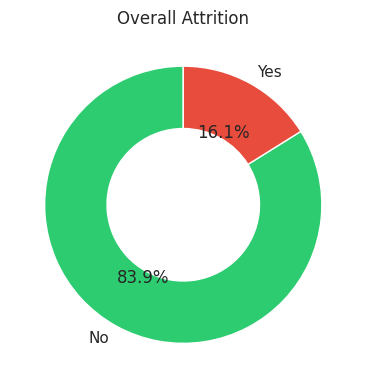

In [5]:
counts = df["Attrition"].value_counts()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=[PALETTE[i] for i in counts.index], wedgeprops=dict(width=0.45))
ax.set_title("Overall Attrition")
plt.savefig("figs/01_overall.png", dpi=150, bbox_inches="tight"); plt.show()

### 5.2 Attrition rate by category

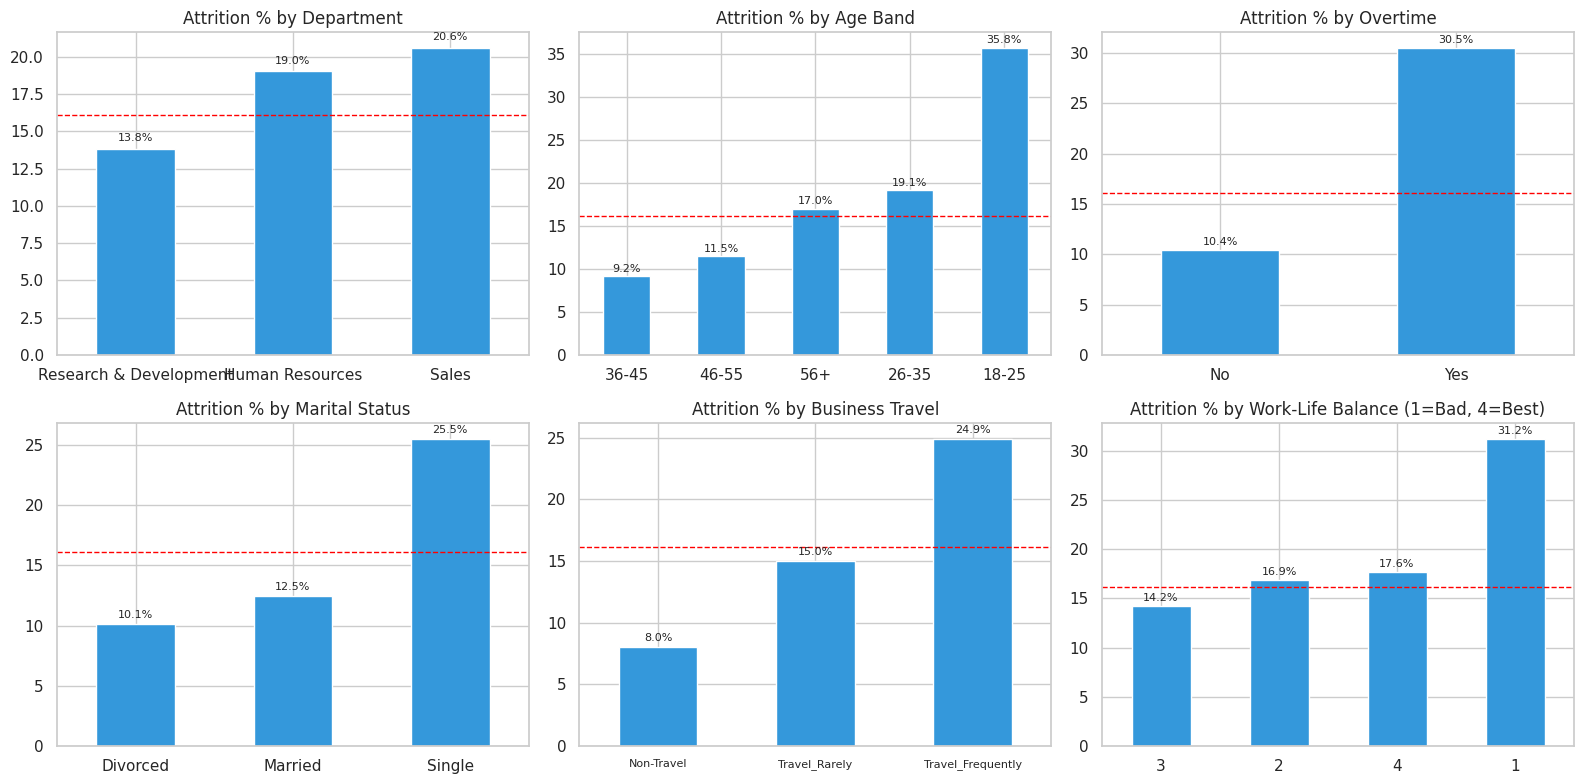

In [6]:
def rate_plot(ax, col, title, horizontal=False):
    g = df.groupby(col, observed=True)["AttritionFlag"].mean().mul(100).sort_values()
    if horizontal:
        g.plot.barh(ax=ax, color="#3498db")
        for i, v in enumerate(g): ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
    else:
        g.plot.bar(ax=ax, color="#3498db", rot=0)
        for i, v in enumerate(g): ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=8)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")
    ax.axvline(overall, color="red", ls="--", lw=1) if horizontal else ax.axhline(overall, color="red", ls="--", lw=1)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
rate_plot(axes[0, 0], "Department", "Attrition % by Department")
rate_plot(axes[0, 1], "AgeBand", "Attrition % by Age Band")
rate_plot(axes[0, 2], "OverTime", "Attrition % by Overtime")
rate_plot(axes[1, 0], "MaritalStatus", "Attrition % by Marital Status")
rate_plot(axes[1, 1], "BusinessTravel", "Attrition % by Business Travel")
rate_plot(axes[1, 2], "WorkLifeBalance", "Attrition % by Work-Life Balance (1=Bad, 4=Best)")
for a in axes[1, 1:2]: a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig("figs/02_rates.png", dpi=150, bbox_inches="tight"); plt.show()

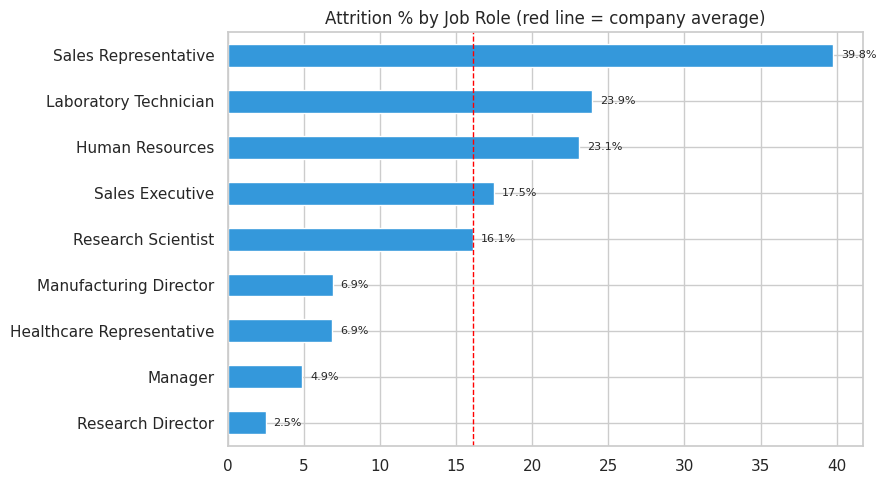

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
rate_plot(ax, "JobRole", "Attrition % by Job Role (red line = company average)", horizontal=True)
plt.tight_layout(); plt.savefig("figs/03_jobrole.png", dpi=150, bbox_inches="tight"); plt.show()

### 5.3 Income, satisfaction and tenure

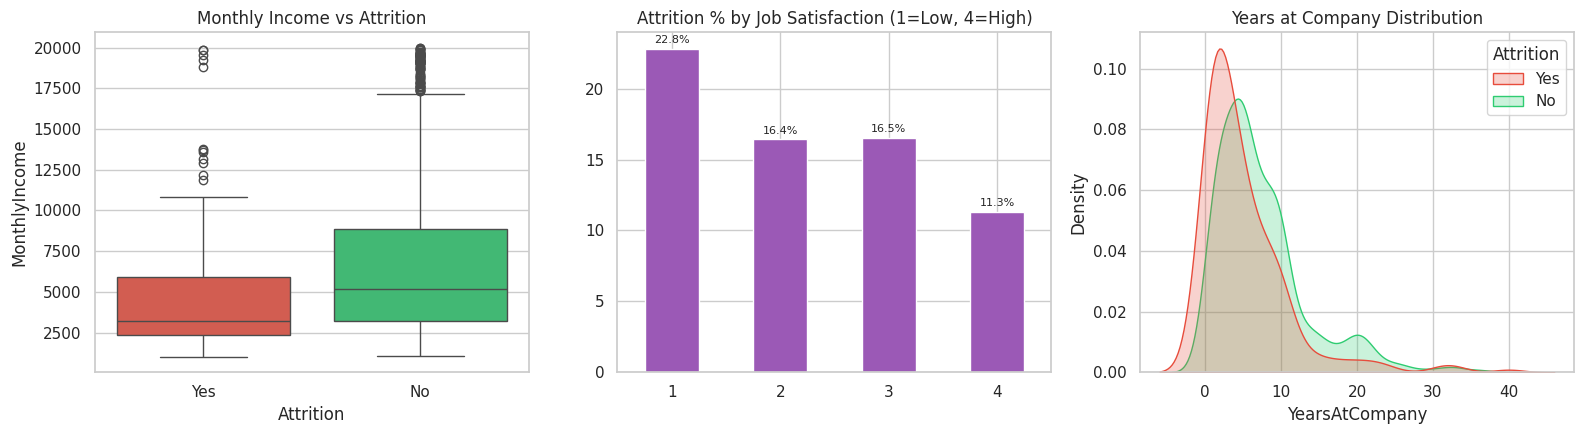

Attrition
No     5204.0
Yes    3202.0
Name: Median monthly income, dtype: float64


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", palette=PALETTE, ax=axes[0])
axes[0].set_title("Monthly Income vs Attrition")
sat = df.groupby("JobSatisfaction")["AttritionFlag"].mean().mul(100)
sat.plot.bar(ax=axes[1], color="#9b59b6", rot=0)
axes[1].set_title("Attrition % by Job Satisfaction (1=Low, 4=High)"); axes[1].set_xlabel("")
for i, v in enumerate(sat): axes[1].text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=8)
sns.kdeplot(data=df, x="YearsAtCompany", hue="Attrition", palette=PALETTE, fill=True, common_norm=False, ax=axes[2])
axes[2].set_title("Years at Company Distribution")
plt.tight_layout(); plt.savefig("figs/04_income_sat_tenure.png", dpi=150, bbox_inches="tight"); plt.show()
print(df.groupby("Attrition")["MonthlyIncome"].median().rename("Median monthly income"))

### 5.4 Heatmap: Job Level x Tenure

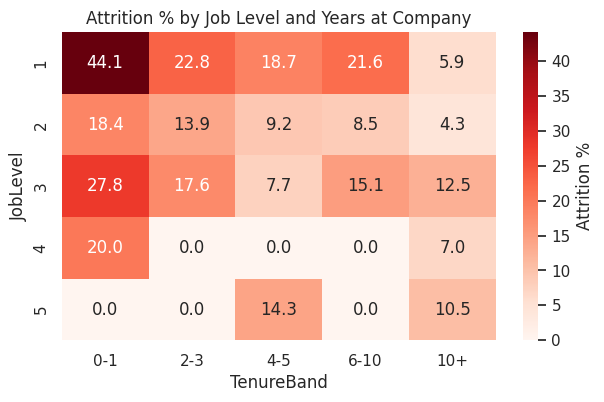

In [9]:
heat = df.pivot_table(index="JobLevel", columns="TenureBand", values="AttritionFlag", aggfunc="mean", observed=True) * 100
plt.figure(figsize=(7, 4))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Attrition %"})
plt.title("Attrition % by Job Level and Years at Company")
plt.savefig("figs/05_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

### 5.5 Correlation of numeric features with attrition

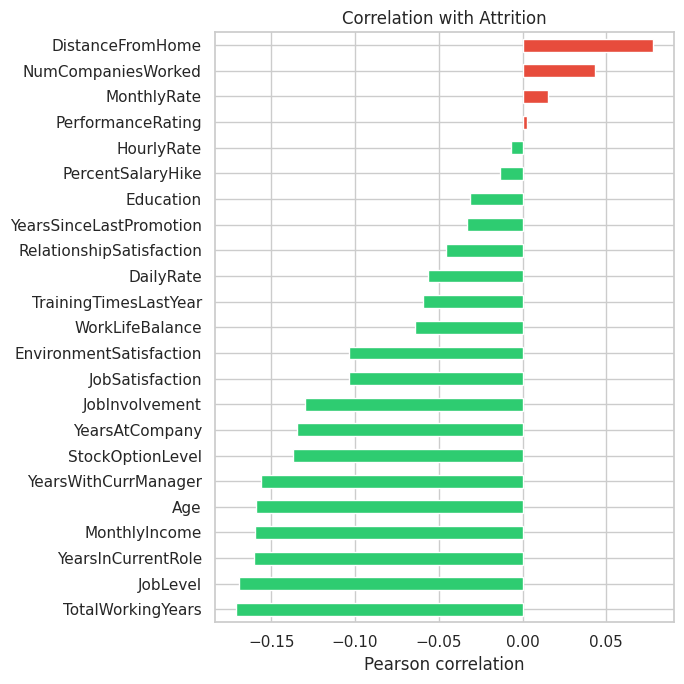

In [10]:
num = df.select_dtypes(include="number").drop(columns=["EmployeeNumber"])
corr = num.corr()["AttritionFlag"].drop("AttritionFlag").sort_values()
plt.figure(figsize=(7, 7))
corr.plot.barh(color=["#e74c3c" if v > 0 else "#2ecc71" for v in corr])
plt.title("Correlation with Attrition"); plt.xlabel("Pearson correlation")
plt.tight_layout(); plt.savefig("figs/06_corr.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Machine Learning: Predicting Attrition
Attrition is the **minority class (~16%)**, so accuracy alone is misleading. We use class weights and judge models on **recall, F1 and ROC-AUC** as well.
Two models are compared: Logistic Regression (baseline, interpretable) and Random Forest.

In [11]:
drop = ["Attrition", "AttritionFlag", "EmployeeNumber", "AgeBand", "TenureBand", "IncomeBand"]
features = [c for c in df.columns if c not in drop]
X = pd.get_dummies(df[features], drop_first=True)
y = df["AttritionFlag"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=3,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
}
THRESHOLD = 0.35  # lowered from 0.5 to catch more leavers (minority class)
rows, probas = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]; probas[name] = p
    pred = (p >= THRESHOLD).astype(int)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p)})
results = pd.DataFrame(rows).set_index("Model").round(3)
results

Train: (1102, 44)  Test: (368, 44)


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.731,0.351,0.797,0.487,0.808
Random Forest,0.812,0.439,0.610,0.511,0.772


Best model by ROC-AUC: Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.95      0.72      0.82       309
        Left       0.35      0.80      0.49        59

    accuracy                           0.73       368
   macro avg       0.65      0.76      0.65       368
weighted avg       0.85      0.73      0.76       368



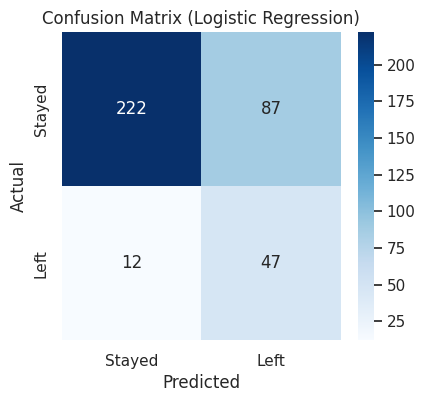

In [12]:
best = results["ROC-AUC"].idxmax()
print("Best model by ROC-AUC:", best)
pred = (probas[best] >= THRESHOLD).astype(int)
print(classification_report(y_test, pred, target_names=["Stayed", "Left"]))
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion Matrix ({best})")
plt.savefig("figs/07_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.1 What drives attrition? (Feature importance)

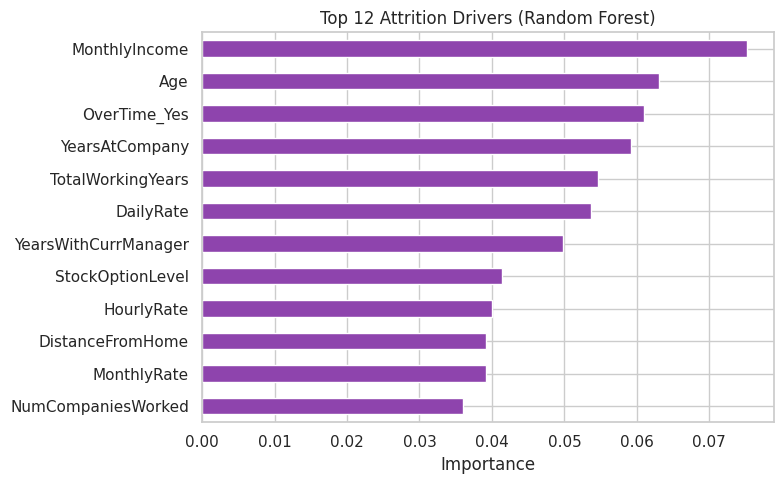

MonthlyIncome           0.075
Age                     0.063
OverTime_Yes            0.061
YearsAtCompany          0.059
TotalWorkingYears       0.055
DailyRate               0.054
YearsWithCurrManager    0.050
StockOptionLevel        0.041
HourlyRate              0.040
DistanceFromHome        0.039
MonthlyRate             0.039
NumCompaniesWorked      0.036
dtype: float64

In [13]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
imp.plot.barh(color="#8e44ad")
plt.title("Top 12 Attrition Drivers (Random Forest)"); plt.xlabel("Importance")
plt.tight_layout(); plt.savefig("figs/08_importance.png", dpi=150, bbox_inches="tight"); plt.show()
imp.iloc[::-1].round(3)

## 7. Employee Risk Scoring
Every employee gets a risk score (0-100). Active employees with a high score are the retention priority.

In [14]:
df["RiskScore"] = (rf.predict_proba(X)[:, 1] * 100).round(1)
df["RiskLevel"] = pd.cut(df["RiskScore"], [-1, 30, 60, 101], labels=["Low", "Medium", "High"])
active = df[df["Attrition"] == "No"]
print("Active employees by risk level:")
print(active["RiskLevel"].value_counts().reindex(["High", "Medium", "Low"]))
print()
cols = ["EmployeeNumber", "Department", "JobRole", "Age", "MonthlyIncome", "OverTime", "YearsAtCompany", "RiskScore"]
active.sort_values("RiskScore", ascending=False)[cols].head(10).reset_index(drop=True)

Active employees by risk level:
RiskLevel
High        12
Medium     160
Low       1061
Name: count, dtype: int64



,EmployeeNumber,Department,JobRole,Age,MonthlyIncome,OverTime,YearsAtCompany,RiskScore
0,411,Sales,Sales Representative,18,1200,No,0,80.5
1,1495,Sales,Sales Representative,24,2033,No,1,71.0
2,2021,Sales,Sales Representative,21,2380,Yes,2,67.5
3,144,Research & Development,Laboratory Technician,22,2871,No,0,66.4
4,1056,Sales,Sales Representative,28,1052,No,1,65.2
5,1974,Research & Development,Laboratory Technician,31,1129,Yes,1,64.7
6,1839,Research & Development,Research Scientist,18,1514,No,0,63.2
7,643,Research & Development,Laboratory Technician,24,2127,No,1,62.1
8,201,Research & Development,Laboratory Technician,19,1483,No,1,61.8
9,1269,Research & Development,Research Scientist,19,2994,Yes,1,61.3


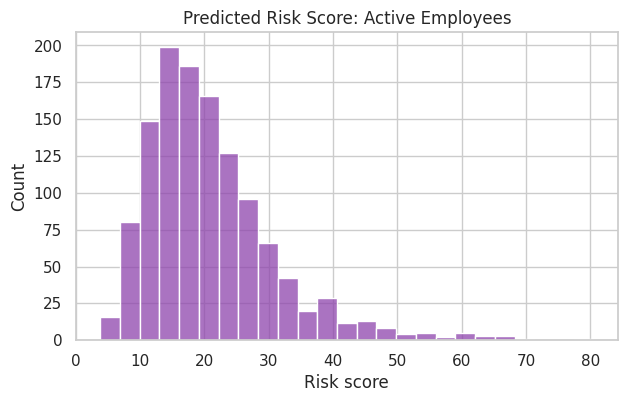

In [15]:
plt.figure(figsize=(7, 4))
sns.histplot(active["RiskScore"], bins=25, color="#8e44ad")
plt.title("Predicted Risk Score: Active Employees"); plt.xlabel("Risk score")
plt.savefig("figs/09_risk_dist.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Key Insights

In [16]:
def r(col, val): return df.loc[df[col] == val, "AttritionFlag"].mean() * 100
role = df.groupby("JobRole")["AttritionFlag"].mean().mul(100)
age = df.groupby("AgeBand", observed=True)["AttritionFlag"].mean().mul(100)
med = df.groupby("Attrition")["MonthlyIncome"].median()
print(f"1. Overall attrition rate: {overall:.1f}%")
print(f"2. Overtime: {r('OverTime','Yes'):.1f}% vs {r('OverTime','No'):.1f}% without overtime ({r('OverTime','Yes')/r('OverTime','No'):.1f}x)")
print(f"3. Highest-risk role: {role.idxmax()} ({role.max():.1f}%)")
print(f"4. Highest-risk age band: {age.idxmax()} ({age.max():.1f}%)")
print(f"5. Single employees: {r('MaritalStatus','Single'):.1f}% vs Married {r('MaritalStatus','Married'):.1f}%")
print(f"6. Median income: leavers ${med['Yes']:,.0f} vs stayers ${med['No']:,.0f}")
print(f"7. Frequent travellers: {r('BusinessTravel','Travel_Frequently'):.1f}% vs non-travel {r('BusinessTravel','Non-Travel'):.1f}%")

1. Overall attrition rate: 16.1%
2. Overtime: 30.5% vs 10.4% without overtime (2.9x)
3. Highest-risk role: Sales Representative (39.8%)
4. Highest-risk age band: 18-25 (35.8%)
5. Single employees: 25.5% vs Married 12.5%
6. Median income: leavers $3,202 vs stayers $5,204
7. Frequent travellers: 24.9% vs non-travel 8.0%


## 9. Recommendations
1. **Control overtime:** overtime staff leave at roughly 3x the rate of others. Rebalance workloads and cap overtime hours.
2. **Protect early-career staff:** employees aged 18-25 at Job Level 1 in their first 1-3 years are the highest-risk group. Add mentoring and clear promotion paths.
3. **Review pay in high-attrition roles** (e.g., Sales Representatives); leavers have a much lower median income.
4. **Reduce frequent business travel** or compensate it with time off.
5. **Run stay-interviews** for employees flagged High risk by the model.
6. **Track satisfaction and work-life balance** through quarterly pulse surveys.

## 10. Conclusion
The analysis shows attrition is concentrated in specific, identifiable groups rather than spread evenly. The Random Forest model gives HR an early-warning list of at-risk employees, and the recommendations target the strongest drivers found in the data.
**Limitation:** the dataset is a snapshot (fictional, created by IBM data scientists), so model precision is moderate; results should guide HR conversations, not individual decisions.